# 05-02 - Semantic Segmentation

You run the lecture's U-Net on one test block, score its answer by pixel, by chip and by building, and watch a mask take shape over the epochs.

We start with the map the fine-tuned model drew over the window. Then we load the frozen-encoder model, predict the block with it, score one chip by hand, score every pixel two ways, match blobs to footprints, replay one chip over the epochs, and compare two chips. At the end you change the threshold.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seg_tools as seg

plt.rcParams["figure.dpi"] = 72

scene = seg.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p05"]
torch_ok = seg.torch_available()
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready


## The map over the window

The cell draws the fine-tuned model's probability of roof over the whole window at 2.4 m beside the mask's share.

roof at or above one half on 10.8% of the window's cells, the mask has 10.8%


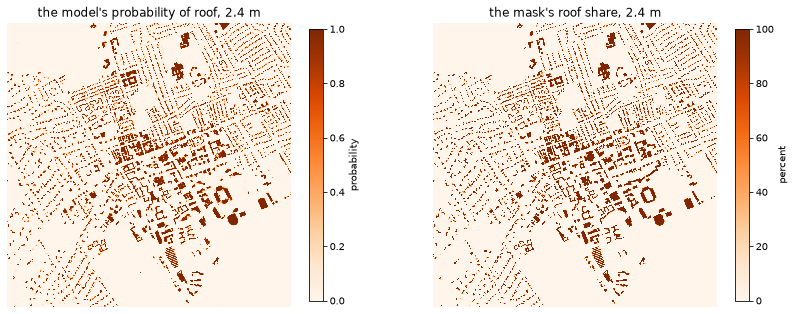

In [2]:
prob_small, transform, crs, res = seg.read_raster("data/prob_2m4.tif")
share, *_ = seg.read_raster("data/mask_2m4.tif")
print(f"roof at or above one half on {(prob_small >= 128).mean():.1%} of the window's cells, "
      f"the mask has {(share >= 50).mean():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
seg.show_image(axes[0], prob_small / 255, "the model's probability of roof, 2.4 m", cmap="Oranges", vmin=0,
               vmax=1, label="probability")
seg.show_image(axes[1], share, "the mask's roof share, 2.4 m", cmap="Oranges", vmin=0, vmax=100,
               label="percent")

One network drew the left picture for all 105 million pixels of the window, chip by chip, in under a minute on a laptop's graphics chip. Dark orange is sure, pale is unsure, white is no roof. Compare it with the mask on the right. The campus, the shopping streets and the neighbourhoods are all there, and the two pictures differ most along the edges of roofs and under the trees. The printed shares say how much roof each one holds at 2.4 m.

## The segmenter as numbers

The cell loads the frozen-encoder U-Net of the lecture from its shipped weights and counts them.

In [3]:
if torch_ok:
    model, provenance = seg.load_model("data/segmenter_frozen.npz")
    c = seg.count_parameters(model)
    print(f"{c['total']:,} weights, {c['encoder']:,} in the encoder, {c['decoder']:,} in the decoder"
          f"   reference {reference['model']['parameters']:,}")
    print(f"run {provenance['run']}, kept at epoch {provenance['best_epoch']}")
    print(f"trained on {provenance['trained_on']}")
else:
    print(seg.NO_TORCH)

12,460,881 weights, 11,176,512 in the encoder, 1,284,369 in the decoder   reference 12,460,881
run frozen, kept at epoch 18
trained on 3600 chips of 256 px at 0.3 m, overlapping, split block


The shipped file holds every weight of the lecture's frozen-encoder run as a half-precision number, 25 MB. The encoder is the ResNet-18 of Lecture 04 with the weights it learned on ImageNet, never moved in this run. The decoder is new, 1.3 million weights that grow the maps back from 8 pixels to 256 and end in one number per pixel. The lecture's main run moved the encoder too and scored higher. This one ships because its encoder is the one you fine-tune yourself in 05-03.

## The block predicted

The cell reads the block and its mask, runs the model over it chip by chip, and draws its map beside the lecture's map from the same weights.

64 chips predicted in 1 s on mps
IoU of your map 0.706, of the shipped map 0.707   reference 0.707


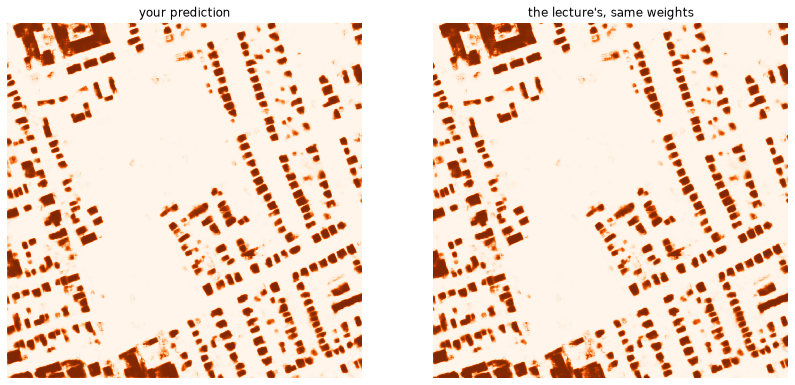

In [4]:
image, transform, crs, res = seg.read_raster("data/block_7.tif")
mask, *_ = seg.read_raster("data/mask_7.tif")
shipped, *_ = seg.read_raster("data/prob_7_frozen.tif")
if torch_ok:
    own = seg.predict_block(model, image)
    print(f"IoU of your map {seg.iou(own >= 0.5, mask > 0):.3f}, of the shipped map "
          f"{seg.iou(shipped >= 128, mask > 0):.3f}   reference {reference['block']['frozen']['iou']:.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    seg.show_image(axes[0], own, "your prediction", cmap="Oranges", vmin=0, vmax=1)
    seg.show_image(axes[1], shipped / 255, "the lecture's, same weights", cmap="Oranges", vmin=0, vmax=1)
else:
    print(seg.NO_TORCH)

The block is 64 chips, read at a stride of 128 pixels with the centre of each kept, so that no chip edge falls on a roof. On a laptop's processor the cell takes well under a minute. The two maps are the same weights on the same pixels on two machines, and the IoUs agree to within a thousandth. The rim differs, because the lecture predicted the block with its neighbours in view. If the library is missing, the shipped map carries the rest of the notebook.

## One chip scored by hand

The cell takes one chip of the block from the fine-tuned model's map, counts its four kinds of pixels and computes the IoU from them.

roof found 29,864, false alarm 2,228, roof missed 1,376, other 32,068
IoU 0.892, pixels right 94.5%


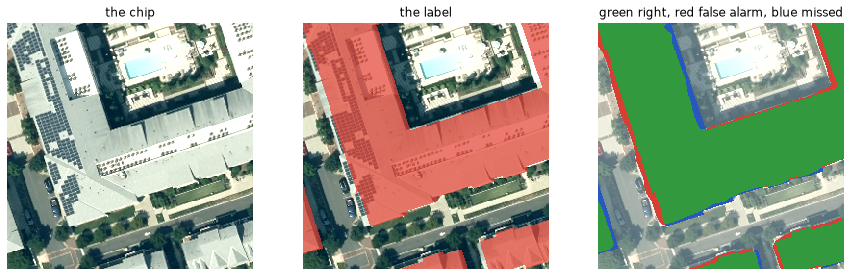

In [5]:
prob, *_ = seg.read_raster("data/prob_7_finetuned.tif")
picture, high = seg.stretch(image), reference["block"]["pair"]["high"]
window = (slice(high["row"], high["row"] + 256), slice(high["col"], high["col"] + 256))
pred, ref = prob[window] >= 128, mask[window] > 0
cm = seg.confusion(pred, ref)
print(f"roof found {cm['tp']:,}, false alarm {cm['fp']:,}, roof missed {cm['fn']:,}, other {cm['tn']:,}")
print(f"IoU {cm['tp'] / (cm['tp'] + cm['fp'] + cm['fn']):.3f}, "
      f"pixels right {(cm['tp'] + cm['tn']) / pred.size:.1%}")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
seg.show_image(axes[0], picture[window], "the chip")
seg.show_mask(axes[1], picture[window], ref, "the label")
seg.show_agreement(axes[2], pred, ref, picture[window], "green right, red false alarm, blue missed")

Four counts score a mask. The roof pixels the model found, the pixels it called roof that are not, the roof pixels it missed, and everything else. Intersection over union is the first count over the sum of the first three, the roof both masks share over the roof either has. The share of pixels right adds the fourth count. In the third picture the errors sit along the edges of the roofs and under the trees. Now the same arithmetic for every pixel of the block.

## All held-out pixels, two ways

The cell scores every chip of the block and pools every pixel, for the fine-tuned map and for the frozen one.

In [6]:
blk = reference["block"]
for name, layer, ref_ in (("fine-tuned", prob, blk["finetuned"]), ("frozen", shipped, blk["frozen"])):
    rows, pooled = seg.chip_scores(layer / 255, mask)
    defined = [row["iou"] for row in rows if row["iou"] is not None]
    print(f"{name:10} per chip {np.mean(defined):.3f} over {len(defined)}, pooled {pooled['iou']:.3f}, "
          f"pixels right {pooled['accuracy']:.1%}   reference {ref_['per_chip_mean']:.3f}, {ref_['iou']:.3f}")
lecture = reference["lecture"]
print(f"the lecture on its five test blocks: {lecture['main']['test_iou']:.3f} chip by chip on 1,125 chips, "
      f"{lecture['stitched']['iou']:.3f} pooled; no building anywhere "
      f"{lecture['stitched']['no_building_accuracy']:.1%} of the pixels right")

fine-tuned per chip 0.719 over 57, pooled 0.744, pixels right 95.3%   reference 0.719, 0.744
frozen     per chip 0.665 over 59, pooled 0.707, pixels right 94.4%   reference 0.665, 0.707
the lecture on its five test blocks: 0.663 chip by chip on 1,125 chips, 0.681 pooled; no building anywhere 85.8% of the pixels right


Two numbers for one map, and both are the IoU. Chip by chip averages the IoU of the chips, and a chip without a roof pixel and without a predicted one has no IoU and is left out, which is why the count is below 64. Pooled counts every pixel of the block at once, so the large roofs weigh more. The lecture's numbers on all five test blocks are lower than this block's, because block 7 is the easy one. The last number is why pixels right flatters.

## Buildings, not pixels

The cell turns the fine-tuned map into blobs, matches every blob to one footprint when their IoU reaches one half, and counts.

338 buildings, 294 blobs, 236 matched at one half   reference 338, 294, 236
precision per object 0.803, recall per object 0.698   reference 0.803, 0.698


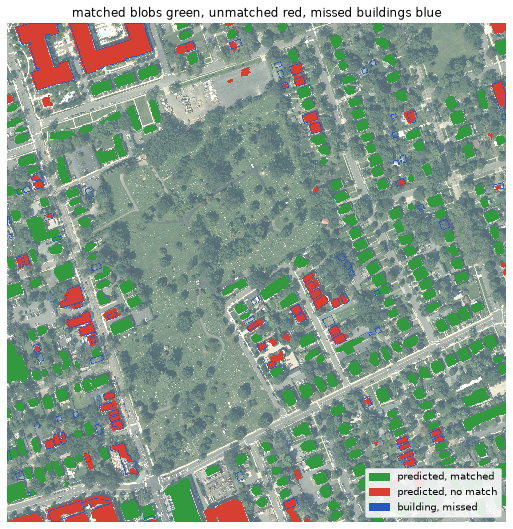

In [7]:
footprints = gpd.read_file("data/layers.gpkg", layer="footprints_7")
ids = seg.rasterise(footprints, transform, mask.shape)
matched = seg.match_objects(prob >= 128, ids, threshold=0.5)
ref_ = reference["block"]["finetuned"]["objects"]
print(f"{matched['reference']} buildings, {matched['predicted']} blobs, {matched['matched']} matched at one "
      f"half   reference {ref_['reference']}, {ref_['predicted']}, {ref_['matched']}")
print(f"precision per object {matched['precision']:.3f}, recall per object {matched['recall']:.3f}"
      f"   reference {ref_['precision']:.3f}, {ref_['recall']:.3f}")
fig, ax = plt.subplots(figsize=(9, 9))
seg.show_objects(ax, picture, matched, ids, "matched blobs green, unmatched red, missed buildings blue")

A town counts buildings, so the map is cut into blobs and each blob is paired with the footprint it overlaps most, as long as the two share at least half of their union. Precision per object is the share of blobs that found a match, recall per object the share of footprints that were found. The buildings missed, in blue, are small, or sit under a tree, or were merged with a neighbour into one blob, which the matching counts once. The threshold of one half is a choice.

## The mask over the epochs

The cell reads one validation chip's probability map after every epoch of the lecture's main run and draws six of the epochs.

a chip of block 2 with 14% roof; the run kept epoch 24 of 30
IoU epoch 1 0.81, epoch 2 0.91, epoch 4 0.93, epoch 8 0.87, epoch 16 0.85, epoch 24 0.89


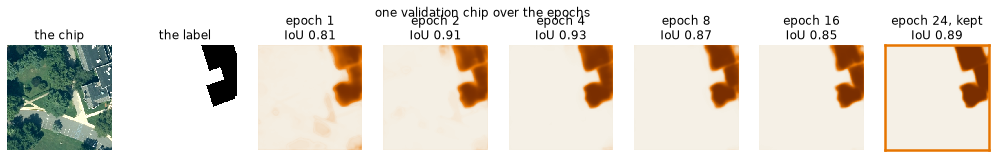

In [8]:
ev = seg.read_npz("data/evolution.npz")
best, shown = int(ev["best_epoch"]), reference["evolution"]["shown"]
print(f"a chip of block {int(ev['block'])} with {float(ev['share']):.0%} roof; the run kept epoch {best} "
      f"of {len(ev['iou'])}")
print("IoU " + ", ".join(f"epoch {e} {ev['iou'][e - 1]:.2f}" for e in shown))
fig = seg.show_evolution(ev["image"], ev["mask"], ev["prob"], ev["iou"], shown, best)

The lecture's loss curve is an average over 900 validation chips, and this is what it is made of. After one epoch the chip's mask already overlaps the volunteers' by four fifths, because the encoder arrived knowing edges and textures from a million photographs. The following epochs sharpen the corners, then the chip wobbles by several hundredths while the average over all the validation chips creeps up to its best. The kept epoch is the one the average chose, not the best epoch of this chip.

## The same pixels right, a different IoU

The cell finds two chips of the block whose shares of pixels right agree and whose IoUs differ most, and draws them.

pixels right 94.3% and 94.5%, IoU 0.47 and 0.89   reference 0.47 and 0.89


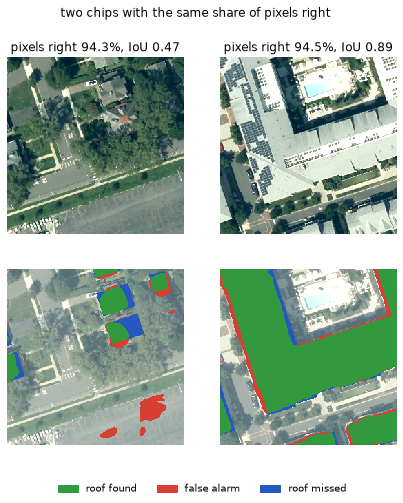

In [9]:
rows, pooled = seg.chip_scores(prob / 255, mask)
low, high = seg.equal_accuracy_pair(rows)
pair = reference["block"]["pair"]
print(f"pixels right {low['accuracy']:.1%} and {high['accuracy']:.1%}, IoU {low['iou']:.2f} and "
      f"{high['iou']:.2f}   reference {pair['low']['iou']:.2f} and {pair['high']['iou']:.2f}")
cut = [(slice(x["row"], x["row"] + 256), slice(x["col"], x["col"] + 256)) for x in (low, high)]
fig = seg.show_two_chips([picture[s] for s in cut], [mask[s] > 0 for s in cut],
                         [prob[s] >= 128 for s in cut], (low, high))

Both chips get the same share of their pixels right, and one is nearly perfect while the other is half wrong. The difference is the roof share. In the left chip the roof is small, so a few hundred missed pixels are most of the roof and almost none of the chip; in the right chip the roof is large and found whole. Pixels right counts the background, which decides it. The IoU counts only the roof. A poster reports the IoU, with the threshold it used.

## Your turn

The map becomes a mask at a probability of one half. Lower the cut to 0.3 and score the block and its buildings again. Run the cell as it is, then change the marked value and run it again.

Which way did precision and recall move, per pixel and per object, and why does the IoU not simply follow one of them? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [10]:
THRESHOLD = 0.5  # change me: 0.3
rows, pooled = seg.chip_scores(prob / 255, mask, threshold=THRESHOLD)
matched = seg.match_objects(prob >= THRESHOLD * 255, ids, threshold=0.5)
print(f"cut at {THRESHOLD}: IoU {pooled['iou']:.3f}, precision per pixel {pooled['precision']:.3f}, "
      f"recall per pixel {pooled['recall']:.3f}")
print(f"objects: {matched['predicted']} blobs, {matched['matched']} matched, precision "
      f"{matched['precision']:.3f}, recall {matched['recall']:.3f}")

cut at 0.5: IoU 0.744, precision per pixel 0.861, recall per pixel 0.846
objects: 294 blobs, 236 matched, precision 0.803, recall 0.698


## Check your understanding

1. Why does the model read the block at a stride of 128 pixels and keep only the centre of each chip?
2. A chip without a roof pixel is left out of the chip-by-chip IoU. What would counting it as zero do to the average, and what as one?
3. Two chips get 95 percent of their pixels right and IoUs of 0.5 and 0.9. Which one would you rather have on a map of buildings, and why?
4. A blob merges two houses. How does the matching at one half count it, and which per-object number does that hurt?

## Where we are

You have run a U-Net over a test block and reproduced the lecture's map to the third decimal, scored one chip by its four counts, scored the block chip by chip and pooled, matched its blobs to the volunteers' footprints, and watched one chip's mask take shape over the epochs. You now know what the IoU is, why pixels right flatters, and which number a town wants. In 05-03 you train a decoder yourself, on 24 chips.

## Further resources

Nothing in this course requires anything below.

- GeoAI with Python, chapter 9 on segmentation and chapter 10 on accuracy, Qiusheng Wu, 2026, https://geoai.gishub.org
- Understanding metric-related pitfalls in image analysis validation, Annika Reinke and colleagues, Nature Methods 21, 2024, https://doi.org/10.1038/s41592-023-02150-0
- Accuracy assessment in convolutional neural network-based deep learning remote sensing studies, Aaron Maxwell, Timothy Warner and Luis Guillén, Remote Sensing 13, 2021

The model, its weights, its outputs and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. The footprints are an OpenStreetMap extract, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright